# Nhiệm vụ 8 — Hồ sơ cụm PCA + K-Means V2

Đọc hồ sơ cụm đã đóng băng của Nhiệm vụ 6 V2: 120 dòng, 13 cột, 60 tháng
development 2019-01-31–2023-12-29, Global K=2. Không huấn luyện lại.
Mean feature gốc đã được Nhiệm vụ 6 tính từ thành viên thực tế; không dựng lại
feature từ inverse PCA và không đọc dữ liệu holdout.

**Cách chạy:** chọn kernel Python 3.11 hoặc mới hơn; Restart Kernel nếu đang dùng
kernel của notebook khác, rồi Run All. Các cell trước bước xuất cuối chỉ đọc,
tính ba bảng và xem biểu đồ. Cell cuối cùng có code mới ghi kết quả Nhiệm vụ 8.
Thư viện cần dùng: numpy, pandas, matplotlib, ipywidgets và IPython.
Nếu kernel thiếu widget, chạy %pip install ipywidgets rồi Restart Kernel.

Mean/Median là thống kê qua 60 hồ sơ tháng, mỗi tháng trọng số bằng nhau:
không phải phân phối của mọi cổ phiếu gộp chung, cũng không phải median từng mã.
Thanh khoản trình bày bằng tỷ VND/phiên. Giữ nhãn kỹ thuật Cụm 0 và Cụm 1.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown
import ipywidgets as widgets

CWD = Path.cwd().resolve()
ROOT = next((p for p in [CWD, *CWD.parents]
             if (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    ROOT = next((p for p in CWD.iterdir()
                 if p.is_dir() and (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở workspace M2_v1, repository hoặc M2/notebooks.')
TASK_DIR = ROOT / 'M2/artifacts/m2-task6-pca-kmeans-v2'
EVAL_DIR = ROOT / 'M2/artifacts/m2-evaluation-pca-kmeans-v2'
PROFILE_PATH = TASK_DIR / 'cluster_profiles.csv'
SOURCE_MANIFEST_PATH = TASK_DIR / 'manifest.json'
REPORT_PATH = ROOT / 'M2/reports/Bao_cao_M2_Nhiem_vu_8_Ho_so_cum_PCA_KMeans_v2.md'
EVIDENCE_PATH = EVAL_DIR / 'task8_profile_evidence.json'
OUTPUT_MANIFEST_PATH = EVAL_DIR / 'task8_manifest.json'
EXPECTED_PROFILE_SHA256 = '9dd6b3528faeee871ba63d8168d45661dc706bd51f61f960422243b340d8e564'

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def immutable_bytes(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if path.read_bytes() != content:
            raise FileExistsError(f'Nội dung khác đã có: {path}; cần phiên bản mới.')
    else:
        with path.open('xb') as stream:
            stream.write(content)

def json_bytes(value):
    return (json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n').encode('utf-8')

def markdown_table(frame):
    def clean(value):
        return str(value).replace('|', r'\|').replace('\n', ' ')
    return '\n'.join(
        ['| ' + ' | '.join(map(clean, frame.columns)) + ' |',
         '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
        + ['| ' + ' | '.join(map(clean, row)) + ' |'
           for row in frame.itertuples(index=False, name=None)])

source_manifest = json.loads(SOURCE_MANIFEST_PATH.read_text(encoding='utf-8'))
assert source_manifest['status'] == 'complete' and source_manifest['task6_exports_complete'] is True
assert source_manifest['artifact_id'] == 'm2-task6-pca-kmeans-v2'
CONFIG = source_manifest['config']
FEATURES = CONFIG['clustering']['features']
DEV_DATES = CONFIG['development_snapshots']
assert CONFIG['protocol_scope'] == 'm2_market_only_v2'
assert CONFIG['clustering']['k'] == 2 and CONFIG['clustering']['algorithm'] == 'pca_kmeans'
assert CONFIG['portfolio_evaluation']['enabled'] is False
assert len(FEATURES) == 8 and len(DEV_DATES) == 60
assert DEV_DATES[0] == '2019-01-31' and DEV_DATES[-1] == '2023-12-29'
PROFILE_HASH, SOURCE_MANIFEST_HASH = sha(PROFILE_PATH), sha(SOURCE_MANIFEST_PATH)
assert PROFILE_HASH == EXPECTED_PROFILE_SHA256 == source_manifest['artifacts']['cluster_profiles.csv']
print('Nguồn:', PROFILE_PATH)
print('Development:', DEV_DATES[0], '→', DEV_DATES[-1], '| Global K=2')
print('Đích xuất sau khi bạn chạy cell cuối:', EVAL_DIR)


Nguồn: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\artifacts\m2-task6-pca-kmeans-v2\cluster_profiles.csv
Development: 2019-01-31 → 2023-12-29 | Global K=2
Đích xuất sau khi bạn chạy cell cuối: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\artifacts\m2-evaluation-pca-kmeans-v2


## Bước 1 — Kiểm tra 120 hồ sơ đầu vào

Chỉ dùng cluster_profiles.csv cho số liệu kinh tế; model JSON chỉ cung cấp
median/IQR thị trường của chính snapshot để chuẩn hóa hình.
Không dùng scaler fit trên 120 centroid hoặc fit chung qua nhiều tháng.


In [2]:
profiles = pd.read_csv(PROFILE_PATH)
assert profiles.columns.tolist() == [
    'snapshot_date', 'raw_cluster_id', 'aligned_cluster_id', 'size', 'size_ratio', *FEATURES]
assert profiles.shape == (120, 13)
assert sorted(profiles.snapshot_date.unique()) == DEV_DATES
assert not profiles.duplicated(['snapshot_date', 'aligned_cluster_id']).any()
assert not profiles.duplicated(['snapshot_date', 'raw_cluster_id']).any()
for column in ['raw_cluster_id', 'aligned_cluster_id']:
    assert profiles.groupby('snapshot_date')[column].apply(lambda s: set(s) == {0, 1}).all()
assert np.isfinite(profiles[['size', 'size_ratio', *FEATURES]].to_numpy(dtype=float)).all()
assert profiles['size'].gt(0).all() and profiles['size'].mod(1).eq(0).all()
assert int(profiles['size'].sum()) == source_manifest['n_assignments']
assert profiles.mdd_126.le(0).all() and profiles.liquidity_21.ge(0).all()
totals = profiles.groupby('snapshot_date')['size'].transform('sum')
assert totals.ge(CONFIG['min_eligible_count']).all()
assert np.allclose(profiles.size_ratio, profiles['size'] / totals, rtol=1e-12, atol=1e-12)
work = profiles.sort_values(['snapshot_date', 'aligned_cluster_id']).copy()
work['liquidity_21_ty_vnd'] = work.liquidity_21 / 1e9
TABLE_FEATURES = [
    'size', 'liquidity_21_ty_vnd', 'beta_126', 'vol_63', 'mdd_126',
    'mom_21', 'mom_63', 'mom_126', 'mom_252']
print('PASS: 120 hồ sơ × 13 cột; đủ 60 tháng, mỗi tháng 2 cụm.')


PASS: 120 hồ sơ × 13 cột; đủ 60 tháng, mỗi tháng 2 cụm.


## Bước 2 — Ba bảng chuẩn

1. Mean và Median qua tháng: 4 × 10; thanh khoản chia 10^9.
2. So sánh Cụm 0/Cụm 1: 9 × 4; chênh lệch có dấu C0 − C1.
3. Quy mô và thanh khoản theo tháng: 60 × 5.

Mean dễ bị các tháng cực đoan chi phối. Median ở đây là trung vị của 60
giá trị mean thành viên của cụm theo tháng, không phải median cổ phiếu trong cụm.


In [3]:
rows = []
for cluster in [0, 1]:
    data = work[work.aligned_cluster_id.eq(cluster)]
    for statistic in ['mean', 'median']:
        rows.append(dict(
            aligned_cluster_id=f'Cụm {cluster} ({statistic.title()})',
            **data[TABLE_FEATURES].agg(statistic).to_dict()))
table1 = pd.DataFrame(rows)
means = work.groupby('aligned_cluster_id')[TABLE_FEATURES].mean()
medians = work.groupby('aligned_cluster_id')[TABLE_FEATURES].median()
table2 = pd.DataFrame({
    'Đặc trưng': TABLE_FEATURES,
    'Cụm 0 (Mean)': means.loc[0].values,
    'Cụm 1 (Mean)': means.loc[1].values,
    'Chênh lệch (Cụm 0 - Cụm 1)': (means.loc[0] - means.loc[1]).values,
})
pivot = work.pivot(
    index='snapshot_date', columns='aligned_cluster_id',
    values=['size', 'liquidity_21_ty_vnd']).reindex(DEV_DATES)
table3 = pd.DataFrame({
    'Snapshot': DEV_DATES,
    'Size Cụm 0': pivot['size'][0].to_numpy(),
    'Size Cụm 1': pivot['size'][1].to_numpy(),
    'Liquidity Cụm 0 (tỷ VND)': pivot['liquidity_21_ty_vnd'][0].to_numpy(),
    'Liquidity Cụm 1 (tỷ VND)': pivot['liquidity_21_ty_vnd'][1].to_numpy(),
})
assert table1.shape == (4, 10) and table2.shape == (9, 4) and table3.shape == (60, 5)
with pd.option_context('display.max_rows', 60, 'display.max_columns', 10):
    display(Markdown('### Bảng 1 — Mean và Median qua 60 tháng'))
    display(table1.round(6))
    display(Markdown('### Bảng 2 — So sánh đối đầu'))
    display(table2.round(6))
    display(Markdown('### Bảng 3 — Quy mô và thanh khoản'))
    display(table3.round(6))


### Bảng 1 — Mean và Median qua 60 tháng

,aligned_cluster_id,size,liquidity_21_ty_vnd,beta_126,vol_63,mdd_126,mom_21,mom_63,mom_126,mom_252
0,Cụm 0 (Mean),12.116667,249.983935,1.377735,0.455133,-0.281996,0.038937,0.240630,0.478703,0.656330
1,Cụm 0 (Median),12.000000,211.375599,1.401596,0.446606,-0.264809,0.028224,0.082456,0.098634,0.110857
2,Cụm 1 (Mean),486.333333,5.019220,0.386404,0.509499,-0.271313,0.017761,0.061301,0.130076,0.253186
3,Cụm 1 (Median),439.000000,3.985669,0.376399,0.511969,-0.250859,0.013843,0.047075,0.083046,0.118693


### Bảng 2 — So sánh đối đầu

,Đặc trưng,Cụm 0 (Mean),Cụm 1 (Mean),Chênh lệch (Cụm 0 - Cụm 1)
0,size,12.116667,486.333333,-474.216667
1,liquidity_21_ty_vnd,249.983935,5.019220,244.964715
2,beta_126,1.377735,0.386404,0.991332
3,vol_63,0.455133,0.509499,-0.054366
4,mdd_126,-0.281996,-0.271313,-0.010682
5,mom_21,0.038937,0.017761,0.021176
6,mom_63,0.240630,0.061301,0.179329
7,mom_126,0.478703,0.130076,0.348627
8,mom_252,0.656330,0.253186,0.403145


### Bảng 3 — Quy mô và thanh khoản

,Snapshot,Size Cụm 0,Size Cụm 1,Liquidity Cụm 0 (tỷ VND),Liquidity Cụm 1 (tỷ VND)
0,2019-01-31,12.0,644.0,87.933290,1.663319
1,2019-02-28,15.0,641.0,106.754440,2.079924
2,2019-03-29,32.0,630.0,74.338543,1.734696
3,2019-04-26,17.0,652.0,76.152261,2.004387
4,2019-05-31,15.0,665.0,88.982126,1.983932
5,2019-06-28,15.0,680.0,78.836126,1.679314
6,2019-07-31,19.0,687.0,76.457101,1.618857
7,2019-08-30,18.0,743.0,79.467491,1.769318
8,2019-09-30,24.0,757.0,58.280176,1.437525
9,2019-10-31,25.0,746.0,56.229245,1.343663


## Bước 3 — Robust Z-Score và động lực phân tách

Z = (mean feature của cụm − market median của tháng) / market IQR của tháng.
Dùng feature thanh khoản theo VND gốc khi áp dụng scaler; chỉ đổi sang tỷ VND
trong các bảng mô tả. Không gộp dữ liệu nhiều tháng để fit chuẩn hóa.

Primary Driver được xác định bằng |mean Z(C0) − mean Z(C1)| lớn nhất qua 60 tháng;
đồng thời đếm số tháng mà feature đó có chênh lệch tuyệt đối lớn nhất.
Đây là chênh lệch của hồ sơ cụm đã quan sát, không phải chứng minh quan hệ nhân quả.


In [4]:
MODELS, MODEL_HASHES = {}, {}
for day in DEV_DATES:
    relative = f'models/{day}.json'
    model_path = TASK_DIR / relative
    MODEL_HASHES[relative] = sha(model_path)
    assert MODEL_HASHES[relative] == source_manifest['artifacts'][relative]
    model = json.loads(model_path.read_text(encoding='utf-8'))
    assert model['config']['features'] == FEATURES and model['config']['k'] == 2
    for feature in FEATURES:
        scaler = model['scaler'][feature]
        assert math.isfinite(scaler['center']) and math.isfinite(scaler['scale'])
        assert scaler['scale'] > 0 and scaler['method'] == 'robust_per_snapshot'
    MODELS[day] = model
z_rows = []
for row in work.itertuples(index=False):
    entry = dict(snapshot_date=row.snapshot_date, aligned_cluster_id=row.aligned_cluster_id)
    for feature in FEATURES:
        scaler = MODELS[row.snapshot_date]['scaler'][feature]
        entry[feature] = (getattr(row, feature) - scaler['center']) / scaler['scale']
    z_rows.append(entry)
z_scores = pd.DataFrame(z_rows)
assert z_scores.shape == (120, 10) and np.isfinite(z_scores[FEATURES].to_numpy()).all()
z_means = z_scores.groupby('aligned_cluster_id')[FEATURES].mean()
driver_delta = z_means.loc[0] - z_means.loc[1]
DRIVER = driver_delta.abs().idxmax()
driver_table = pd.DataFrame({
    'feature': FEATURES,
    'mean_Z_C0': z_means.loc[0].values,
    'mean_Z_C1': z_means.loc[1].values,
    'delta_Z_C0_minus_C1': driver_delta.values,
}).sort_values('delta_Z_C0_minus_C1', key=abs, ascending=False)
monthly_delta = pd.DataFrame({
    f: (z_scores.pivot(index='snapshot_date', columns='aligned_cluster_id', values=f)[0]
        - z_scores.pivot(index='snapshot_date', columns='aligned_cluster_id', values=f)[1])
    for f in FEATURES
}).reindex(DEV_DATES)
monthly_driver = monthly_delta.abs().idxmax(axis=1)
MOMENTUM_COUNTS = {}
for feature in ['mom_21', 'mom_63', 'mom_126', 'mom_252']:
    series = work.pivot(index='snapshot_date', columns='aligned_cluster_id', values=feature)
    MOMENTUM_COUNTS[feature] = int(series[0].gt(series[1]).sum())
liquidity_series = work.pivot(
    index='snapshot_date', columns='aligned_cluster_id', values='liquidity_21_ty_vnd')
LIQUIDITY_HIGHER_COUNT = int(liquidity_series[0].gt(liquidity_series[1]).sum())
positive_z_counts = z_scores.groupby('aligned_cluster_id')[FEATURES].agg(lambda s: int(s.gt(0).sum()))
display(Markdown('### Robust Z-Score trung bình, chưa giới hạn hiển thị'))
display(z_means.round(6))
display(Markdown('### Chênh lệch chuẩn hóa giữa hai cụm'))
display(driver_table.round(6))
print('Primary Driver:', DRIVER, '| delta Z:', float(driver_delta[DRIVER]))
print('Số tháng C0 có momentum cao hơn C1:', MOMENTUM_COUNTS)


### Robust Z-Score trung bình, chưa giới hạn hiển thị

,mom_21,mom_63,mom_126,mom_252,vol_63,mdd_126,beta_126,liquidity_21
aligned_cluster_id,,,,,,,,
0,0.323650,0.863373,0.939383,0.635242,-0.042093,-0.091906,1.544584,244.562158
1,0.139262,0.189404,0.215348,0.244107,0.090247,-0.072072,0.121445,3.674704


### Chênh lệch chuẩn hóa giữa hai cụm

,feature,mean_Z_C0,mean_Z_C1,delta_Z_C0_minus_C1
7,liquidity_21,244.562158,3.674704,240.887454
6,beta_126,1.544584,0.121445,1.423140
2,mom_126,0.939383,0.215348,0.724035
1,mom_63,0.863373,0.189404,0.673969
3,mom_252,0.635242,0.244107,0.391135
0,mom_21,0.323650,0.139262,0.184388
4,vol_63,-0.042093,0.090247,-0.132340
5,mdd_126,-0.091906,-0.072072,-0.019834


Primary Driver: liquidity_21 | delta Z: 240.88745426756316
Số tháng C0 có momentum cao hơn C1: {'mom_21': 33, 'mom_63': 41, 'mom_126': 38, 'mom_252': 33}


## Bước 4 — Radar và Heatmap theo snapshot

Radar hiển thị Z trong [-3,3]. Tọa độ vẽ là Z+3 để giá trị âm có bán kính hợp lệ;
nhãn vẫn là Z và vòng xám nét đứt tại Z=0 là market median đã lưu.
Dấu * cho biết giá trị thật vượt biên; chỉ hình bị giới hạn, dữ liệu/model không bị clipping.
Hai điểm cùng nằm ở biên +3 không có nghĩa chúng có cùng giá trị.

Heatmap 2×8 dùng RdBu_r, trung hòa 0, màu bão hòa ngoài ±3; số annot giữ Z thật
với hai chữ số thập phân. Bảng Z thật ngay dưới hình giúp đọc độ lớn bị che trên Radar.
Mặc định xem và xuất snapshot cuối 2023-12-29. Dropdown chỉ thay hình xem;
không đổi nội dung hai PNG cuối kỳ sẽ bàn giao.


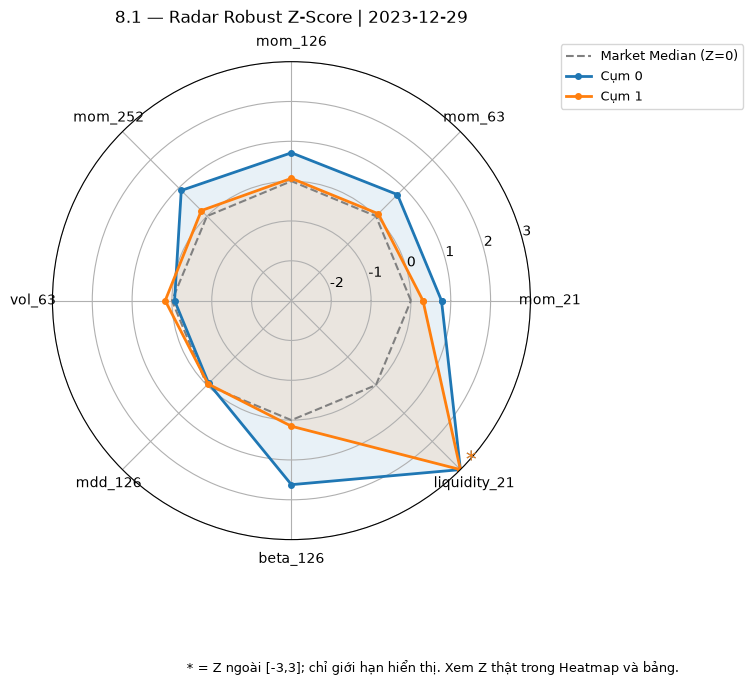

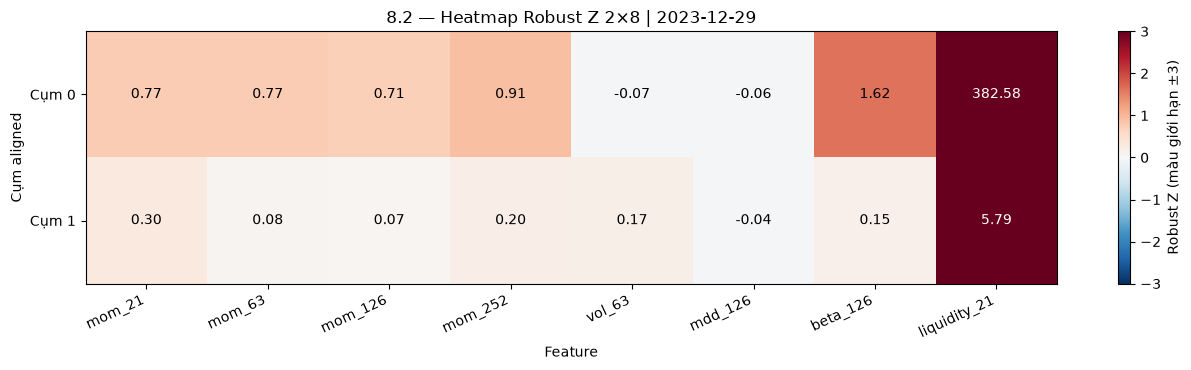

### Z thật tại 2023-12-29; không cắt dữ liệu

,mom_21,mom_63,mom_126,mom_252,vol_63,mdd_126,beta_126,liquidity_21
aligned_cluster_id,,,,,,,,
0,0.768041,0.765084,0.711783,0.911802,-0.066364,-0.062703,1.620518,382.583514
1,0.303089,0.084377,0.070046,0.197954,0.169186,-0.040561,0.153658,5.791490


In [5]:
def render_snapshot(day):
    assert day in DEV_DATES
    data = z_scores[z_scores.snapshot_date.eq(day)].set_index('aligned_cluster_id')[FEATURES].sort_index()
    angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False)
    closed_angles = np.r_[angles, angles[0]]
    fig, ax = plt.subplots(figsize=(8.8, 8.0), subplot_kw={'polar': True})
    ax.set_xticks(angles, FEATURES)
    ax.set_yticks(range(7), [str(value) for value in range(-3, 4)])
    ax.set_ylim(0, 6)
    ax.set_rlabel_position(15)
    ax.plot(closed_angles, [3] * 9, color='gray', linestyle='--', label='Market Median (Z=0)')
    for cluster, color in [(0, '#1f77b4'), (1, '#ff7f0e')]:
        true_z = data.loc[cluster].to_numpy(dtype=float)
        display_z = np.clip(true_z, -3, 3) + 3
        ax.plot(closed_angles, np.r_[display_z, display_z[0]], color=color,
                linewidth=2, marker='o', markersize=4, label=f'Cụm {cluster}')
        ax.fill(closed_angles, np.r_[display_z, display_z[0]], color=color, alpha=0.10)
        for angle, position, value in zip(angles, display_z, true_z):
            if abs(value) > 3:
                ax.annotate('*', (angle, position), xytext=(4, 3), textcoords='offset points',
                            color=color, fontsize=15)
    ax.set_title(f'8.1 — Radar Robust Z-Score | {day}', pad=28)
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1.05), fontsize=9)
    fig.text(0.5, 0.025,
             '* = Z ngoài [-3,3]; chỉ giới hạn hiển thị. Xem Z thật trong Heatmap và bảng.',
             ha='center', fontsize=9)
    fig.tight_layout(rect=(0.04, 0.06, 0.84, 0.95))
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    radar_bytes = buffer.getvalue()
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(13.2, 3.8))
    values = data.to_numpy(dtype=float)
    image = ax.imshow(values, cmap='RdBu_r',
                      norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3), aspect='auto')
    for row in range(2):
        for column in range(8):
            value = values[row, column]
            ax.text(column, row, f'{value:.2f}', ha='center', va='center',
                    color='white' if abs(value) >= 1.7 else 'black', fontsize=10)
    ax.set_xticks(range(8), FEATURES, rotation=25, ha='right')
    ax.set_yticks([0, 1], ['Cụm 0', 'Cụm 1'])
    ax.set(title=f'8.2 — Heatmap Robust Z 2×8 | {day}', xlabel='Feature', ylabel='Cụm aligned')
    fig.colorbar(image, ax=ax, label='Robust Z (màu giới hạn ±3)')
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    heatmap_bytes = buffer.getvalue()
    plt.show()
    plt.close(fig)
    display(Markdown(f'### Z thật tại {day}; không cắt dữ liệu'))
    display(data.round(6))
    return {'radar_chart.png': radar_bytes, 'heatmap.png': heatmap_bytes}

DEFAULT_FIGURE_SNAPSHOT = DEV_DATES[-1]
DEFAULT_FIGURES = render_snapshot(DEFAULT_FIGURE_SNAPSHOT)


In [6]:
selector = widgets.Dropdown(
    options=DEV_DATES, value=DEFAULT_FIGURE_SNAPSHOT, description='Snapshot:',
    layout=widgets.Layout(width='310px'))
plot_output = widgets.Output()

def on_snapshot_change(change):
    if change.get('name') != 'value' or change.get('new') == change.get('old'):
        return
    with plot_output:
        plot_output.clear_output(wait=True)
        render_snapshot(change['new'])

selector.observe(on_snapshot_change, names='value')
display(selector, plot_output)
print('Dropdown có 60 tháng; ảnh bàn giao vẫn là', DEFAULT_FIGURE_SNAPSHOT)


Dropdown(description='Snapshot:', index=59, layout=Layout(width='310px'), options=('2019-01-31', '2019-02-28',…

Output()

Dropdown có 60 tháng; ảnh bàn giao vẫn là 2023-12-29


## Bước 5 — Biện luận theo bằng chứng

Đọc cả Mean và Median, Z thật và số tháng giữ đặc tính. Không đặt sẵn nhãn
“dẫn dắt” hay “thờ ơ” cho mọi thời điểm. Thanh khoản cao hơn cụm kia không đồng nghĩa
cụm còn lại thấp hơn market median. Beta khác với tổng biến động vol_63.
Chỉ đánh giá tính nhất quán của hồ sơ trong 2019–2023; ARI/chuyển cụm thuộc Nhiệm vụ 9.


In [7]:
latest_z = z_scores[z_scores.snapshot_date.eq(DEFAULT_FIGURE_SNAPSHOT)].set_index('aligned_cluster_id')
SYNTHESIS = f'''## A — Chân dung kinh tế

Cụm 0 là nhóm nhỏ có thanh khoản bình quân cao hơn Cụm 1:
size Mean/Median = {means.loc[0,'size']:.4f}/{medians.loc[0,'size']:.4f} mã,
liquidity Mean/Median = {means.loc[0,'liquidity_21_ty_vnd']:.6f}/{medians.loc[0,'liquidity_21_ty_vnd']:.6f}
tỷ VND/phiên. Cụm 1 có size Mean/Median =
{means.loc[1,'size']:.4f}/{medians.loc[1,'size']:.4f} mã và liquidity Mean/Median =
{means.loc[1,'liquidity_21_ty_vnd']:.6f}/{medians.loc[1,'liquidity_21_ty_vnd']:.6f} tỷ VND/phiên.

Beta Mean C0/C1 = {means.loc[0,'beta_126']:.6f}/{means.loc[1,'beta_126']:.6f};
vol_63 Mean C0/C1 = {means.loc[0,'vol_63']:.6f}/{means.loc[1,'vol_63']:.6f}.
Beta cao hơn không có nghĩa mọi thước đo rủi ro đều cao hơn.
Mean mom_252 C0/C1 = {means.loc[0,'mom_252']:.6f}/{means.loc[1,'mom_252']:.6f},
nhưng Median = {medians.loc[0,'mom_252']:.6f}/{medians.loc[1,'mom_252']:.6f}:
cần đọc hai độ đo cùng nhau, tránh mô tả Mean như đặc điểm bền vững của mọi tháng/mọi mã.

Z thanh khoản trung bình C0/C1 =
{z_means.loc[0,'liquidity_21']:.6f}/{z_means.loc[1,'liquidity_21']:.6f}.
Cả hai cụm có Z thanh khoản dương lần lượt
{int(positive_z_counts.loc[0,'liquidity_21'])}/{int(positive_z_counts.loc[1,'liquidity_21'])}
trên 60 tháng. Vì thế giữ tên Cụm 0/Cụm 1 với mô tả tương đối;
không gán Cụm 1 là “thờ ơ” hoặc dưới market median chỉ vì thấp hơn Cụm 0.

## B — Động lực phân tách chính và tính nhất quán

Primary Driver theo chênh lệch chuẩn hóa là {DRIVER}:
delta Mean Z(C0−C1) = {driver_delta[DRIVER]:.6f};
đứng đầu độ lớn chênh lệch ở {int(monthly_driver.eq(DRIVER).sum())}/60 tháng.
Đây là động lực hình học của hồ sơ đã quan sát, chưa phải bằng chứng dòng tiền ròng,
đầu cơ hay quan hệ nhân quả.

C0 có thanh khoản cao hơn C1 ở {LIQUIDITY_HIGHER_COUNT}/60 tháng. Số tháng
C0 có momentum cao hơn C1 theo mom_21/mom_63/mom_126/mom_252 là
{MOMENTUM_COUNTS['mom_21']}/{MOMENTUM_COUNTS['mom_63']}/{MOMENTUM_COUNTS['mom_126']}/{MOMENTUM_COUNTS['mom_252']}
trên 60 tháng: không diễn giải đây là cụm luôn dẫn dắt giá.
Z mom_63 trung bình C0/C1 =
{z_means.loc[0,'mom_63']:.6f}/{z_means.loc[1,'mom_63']:.6f}.

Tại {DEFAULT_FIGURE_SNAPSHOT}, Z liquidity thật C0/C1 =
{latest_z.loc[0,'liquidity_21']:.6f}/{latest_z.loc[1,'liquidity_21']:.6f}.
Radar giới hạn hiển thị ±3 có thể che độ lớn; Heatmap và bảng Z giữ số thật.
Không dùng ví dụ 04/2024 hoặc 07/2024 vì nằm ngoài development và thuộc holdout V2.

## C — Tính khả thi cho M3 và giới hạn

Chênh lệch thanh khoản là đầu vào mô tả để M3 xây dựng giả định thực thi.
Mean thanh khoản của cụm không đủ chứng minh một quỹ giải ngân được mà không trượt giá:
còn thiếu quy mô vốn, trọng số từng mã, phân phối thanh khoản thành viên,
tỷ lệ tham gia giao dịch và mô hình chi phí. Không suy khả năng hấp thụ vốn của từng
cổ phiếu từ mean của nhóm, đặc biệt khi nhóm nhỏ hoặc có quan sát cực đoan.

Mean/Median và các kiểm tra dấu ở trên là thống kê qua hồ sơ tháng;
không chứng minh thành viên cố định. Nhiệm vụ 9 mới đánh giá ổn định nhãn/chuyển cụm.
Không khuyến nghị mua/bán, không dùng return/Sharpe, không backtest và không mở holdout.
'''
display(Markdown(SYNTHESIS))


## A — Chân dung kinh tế

Cụm 0 là nhóm nhỏ có thanh khoản bình quân cao hơn Cụm 1:
size Mean/Median = 12.1167/12.0000 mã,
liquidity Mean/Median = 249.983935/211.375599
tỷ VND/phiên. Cụm 1 có size Mean/Median =
486.3333/439.0000 mã và liquidity Mean/Median =
5.019220/3.985669 tỷ VND/phiên.

Beta Mean C0/C1 = 1.377735/0.386404;
vol_63 Mean C0/C1 = 0.455133/0.509499.
Beta cao hơn không có nghĩa mọi thước đo rủi ro đều cao hơn.
Mean mom_252 C0/C1 = 0.656330/0.253186,
nhưng Median = 0.110857/0.118693:
cần đọc hai độ đo cùng nhau, tránh mô tả Mean như đặc điểm bền vững của mọi tháng/mọi mã.

Z thanh khoản trung bình C0/C1 =
244.562158/3.674704.
Cả hai cụm có Z thanh khoản dương lần lượt
60/60
trên 60 tháng. Vì thế giữ tên Cụm 0/Cụm 1 với mô tả tương đối;
không gán Cụm 1 là “thờ ơ” hoặc dưới market median chỉ vì thấp hơn Cụm 0.

## B — Động lực phân tách chính và tính nhất quán

Primary Driver theo chênh lệch chuẩn hóa là liquidity_21:
delta Mean Z(C0−C1) = 240.887454;
đứng đầu độ lớn chênh lệch ở 60/60 tháng.
Đây là động lực hình học của hồ sơ đã quan sát, chưa phải bằng chứng dòng tiền ròng,
đầu cơ hay quan hệ nhân quả.

C0 có thanh khoản cao hơn C1 ở 60/60 tháng. Số tháng
C0 có momentum cao hơn C1 theo mom_21/mom_63/mom_126/mom_252 là
33/41/38/33
trên 60 tháng: không diễn giải đây là cụm luôn dẫn dắt giá.
Z mom_63 trung bình C0/C1 =
0.863373/0.189404.

Tại 2023-12-29, Z liquidity thật C0/C1 =
382.583514/5.791490.
Radar giới hạn hiển thị ±3 có thể che độ lớn; Heatmap và bảng Z giữ số thật.
Không dùng ví dụ 04/2024 hoặc 07/2024 vì nằm ngoài development và thuộc holdout V2.

## C — Tính khả thi cho M3 và giới hạn

Chênh lệch thanh khoản là đầu vào mô tả để M3 xây dựng giả định thực thi.
Mean thanh khoản của cụm không đủ chứng minh một quỹ giải ngân được mà không trượt giá:
còn thiếu quy mô vốn, trọng số từng mã, phân phối thanh khoản thành viên,
tỷ lệ tham gia giao dịch và mô hình chi phí. Không suy khả năng hấp thụ vốn của từng
cổ phiếu từ mean của nhóm, đặc biệt khi nhóm nhỏ hoặc có quan sát cực đoan.

Mean/Median và các kiểm tra dấu ở trên là thống kê qua hồ sơ tháng;
không chứng minh thành viên cố định. Nhiệm vụ 9 mới đánh giá ổn định nhãn/chuyển cụm.
Không khuyến nghị mua/bán, không dùng return/Sharpe, không backtest và không mở holdout.


## Bước 6 — Xuất kết quả Nhiệm vụ 8

Cell code tiếp theo mới ghi radar_chart.png và heatmap.png của snapshot cuối,
báo cáo Markdown và JSON bằng chứng/checksum riêng của Task 8.
Không thay quality_summary.csv hoặc manifest.json của Nhiệm vụ 7.
Nếu tệp đã tồn tại và khác nội dung, notebook dừng để bảo toàn evidence;
chạy lại cùng nguồn sẽ kiểm chứng cùng nội dung.


In [8]:
assert sha(PROFILE_PATH) == PROFILE_HASH and sha(SOURCE_MANIFEST_PATH) == SOURCE_MANIFEST_HASH
for relative, expected in MODEL_HASHES.items():
    assert sha(TASK_DIR / relative) == expected
assert set(DEFAULT_FIGURES) == {'radar_chart.png', 'heatmap.png'}
assert table1.shape == (4, 10) and table2.shape == (9, 4) and table3.shape == (60, 5)
for name, content in DEFAULT_FIGURES.items():
    immutable_bytes(EVAL_DIR / name, content)
evidence = dict(
    table1=table1.to_dict('records'), table2=table2.to_dict('records'),
    table3=table3.to_dict('records'), robust_z_scores=z_scores.to_dict('records'),
    driver_table=driver_table.to_dict('records'), momentum_higher_counts=MOMENTUM_COUNTS,
    monthly_driver_counts={str(k):int(v) for k,v in monthly_driver.value_counts().items()},
    mean_median_scope='unweighted_across_60_monthly_cluster_profiles',
    normalization='(cluster_mean - saved_market_median) / saved_market_IQR',
    display_only_limits=[-3, 3], default_figure_snapshot=DEFAULT_FIGURE_SNAPSHOT,
)
immutable_bytes(EVIDENCE_PATH, json_bytes(evidence))
report = (
    '# Báo cáo Nhiệm vụ 8 — Hồ sơ cụm PCA + K-Means V2\n\n'
    + f'Nguồn profile SHA-256: {PROFILE_HASH}.\n\n'
    + '60 development snapshots, K=2, 120 hồ sơ trên 8 feature gốc. '
    + 'Đọc scaler đã fit của đúng snapshot; không huấn luyện hoặc inverse PCA lại.\n\n'
    + '## Bảng 1 — Mean/Median qua tháng\n\n' + markdown_table(table1.round(6)) + '\n\n'
    + '## Bảng 2 — Chênh lệch C0−C1\n\n' + markdown_table(table2.round(6)) + '\n\n'
    + '## Bảng 3 — Quy mô và thanh khoản\n\n' + markdown_table(table3.round(6)) + '\n\n'
    + '## Chênh lệch Robust Z thật\n\n' + markdown_table(driver_table.round(6)) + '\n\n'
    + '![Radar cuối kỳ](../artifacts/m2-evaluation-pca-kmeans-v2/radar_chart.png)\n\n'
    + '![Heatmap cuối kỳ](../artifacts/m2-evaluation-pca-kmeans-v2/heatmap.png)\n\n'
    + SYNTHESIS
)
immutable_bytes(REPORT_PATH, report.encode('utf-8'))
output_manifest = dict(
    artifact_id='m2-task8-pca-kmeans-profiling-v2', status='complete',
    source_artifact_id=source_manifest['artifact_id'],
    source_profile_sha256=PROFILE_HASH, source_manifest_sha256=SOURCE_MANIFEST_HASH,
    source_models_sha256=MODEL_HASHES, n_snapshots=60, n_profiles=120, k=2,
    table_shapes=[[4, 10], [9, 4], [60, 5]], no_refit=True, holdout_accessed=False,
    figures_snapshot=DEFAULT_FIGURE_SNAPSHOT, display_only_limits=[-3, 3],
    primary_driver=DRIVER, primary_driver_delta_z=float(driver_delta[DRIVER]),
    artifacts={p.relative_to(EVAL_DIR).as_posix():sha(p)
               for p in [EVAL_DIR/'radar_chart.png', EVAL_DIR/'heatmap.png', EVIDENCE_PATH]},
    report={REPORT_PATH.relative_to(ROOT).as_posix():sha(REPORT_PATH)},
)
for relative, expected in output_manifest['artifacts'].items():
    assert sha(EVAL_DIR / relative) == expected
immutable_bytes(OUTPUT_MANIFEST_PATH, json_bytes(output_manifest))
print('PASS nhiệm vụ 8 — PCA + K-Means V2:', OUTPUT_MANIFEST_PATH)
print('Báo cáo:', REPORT_PATH)


PASS nhiệm vụ 8 — PCA + K-Means V2: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\artifacts\m2-evaluation-pca-kmeans-v2\task8_manifest.json
Báo cáo: C:\Users\HOME\Desktop\M2_v1\Risk-Adjusted-Momentum-Clustering-m2-clustering-experiment\M2\reports\Bao_cao_M2_Nhiem_vu_8_Ho_so_cum_PCA_KMeans_v2.md


## A — Chân dung kinh tế

Cụm 0 là nhóm nhỏ có thanh khoản bình quân cao hơn Cụm 1:
size Mean/Median = 12.1167/12.0000 mã,
liquidity Mean/Median = 249.983935/211.375599
tỷ VND/phiên. Cụm 1 có size Mean/Median =
486.3333/439.0000 mã và liquidity Mean/Median =
5.019220/3.985669 tỷ VND/phiên.

Beta Mean C0/C1 = 1.377735/0.386404;
vol_63 Mean C0/C1 = 0.455133/0.509499.
Beta cao hơn không có nghĩa mọi thước đo rủi ro đều cao hơn.
Mean mom_252 C0/C1 = 0.656330/0.253186,
nhưng Median = 0.110857/0.118693:
cần đọc hai độ đo cùng nhau, tránh mô tả Mean như đặc điểm bền vững của mọi tháng/mọi mã.

Z thanh khoản trung bình C0/C1 =
244.562158/3.674704.
Cả hai cụm có Z thanh khoản dương lần lượt
60/60
trên 60 tháng. Vì thế giữ tên Cụm 0/Cụm 1 với mô tả tương đối;
không gán Cụm 1 là “thờ ơ” hoặc dưới market median chỉ vì thấp hơn Cụm 0.

## B — Động lực phân tách chính và tính nhất quán

Primary Driver theo chênh lệch chuẩn hóa là liquidity_21:
delta Mean Z(C0−C1) = 240.887454;
đứng đầu độ lớn chênh lệch ở 60/60 tháng.
Đây là động lực hình học của hồ sơ đã quan sát, chưa phải bằng chứng dòng tiền ròng,
đầu cơ hay quan hệ nhân quả.

C0 có thanh khoản cao hơn C1 ở 60/60 tháng. Số tháng
C0 có momentum cao hơn C1 theo mom_21/mom_63/mom_126/mom_252 là
33/41/38/33
trên 60 tháng: không diễn giải đây là cụm luôn dẫn dắt giá.
Z mom_63 trung bình C0/C1 =
0.863373/0.189404.

Tại 2023-12-29, Z liquidity thật C0/C1 =
382.583514/5.791490.
Radar giới hạn hiển thị ±3 có thể che độ lớn; Heatmap và bảng Z giữ số thật.
Không dùng ví dụ 04/2024 hoặc 07/2024 vì nằm ngoài development và thuộc holdout V2.

## C — Tính khả thi cho M3 và giới hạn

Chênh lệch thanh khoản là đầu vào mô tả để M3 xây dựng giả định thực thi.
Mean thanh khoản của cụm không đủ chứng minh một quỹ giải ngân được mà không trượt giá:
còn thiếu quy mô vốn, trọng số từng mã, phân phối thanh khoản thành viên,
tỷ lệ tham gia giao dịch và mô hình chi phí. Không suy khả năng hấp thụ vốn của từng
cổ phiếu từ mean của nhóm, đặc biệt khi nhóm nhỏ hoặc có quan sát cực đoan.

Mean/Median và các kiểm tra dấu ở trên là thống kê qua hồ sơ tháng;
không chứng minh thành viên cố định. Nhiệm vụ 9 mới đánh giá ổn định nhãn/chuyển cụm.
Không khuyến nghị mua/bán, không dùng return/Sharpe, không backtest và không mở holdout.

